## 1. Индекс файлов

Собираем таблицу `path, dataset, split, label` (0 – real, 1 – fake): 140k целиком, OpenForensics – подвыборка 10 тыс.

In [1]:
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import COLORS, RAW_DIR
from src.data_index import build_index

index, mismatches = build_index()
index.head()

,path,dataset,split,label
0,140k/real_vs_fake/real-vs-fake/train/real/3135...,140k,train,0
1,140k/real_vs_fake/real-vs-fake/train/real/0288...,140k,train,0
2,140k/real_vs_fake/real-vs-fake/train/real/3398...,140k,train,0
3,140k/real_vs_fake/real-vs-fake/train/real/5387...,140k,train,0
4,140k/real_vs_fake/real-vs-fake/train/real/2414...,140k,train,0


Метка 140k берётся из папки `real/fake`. Расхождения с `label_str` и с `label` из CSV (там 1 – real, 0 – fake):

In [2]:
mismatches

{'label_str': 0, 'label': 0}

Проверки: пути существуют, нет повторов, число файлов на диске.

In [3]:
missing = (~index["path"].map(lambda p: (RAW_DIR / p).exists())).sum()
duplicates = index["path"].duplicated().sum()
files_140k = sum(1 for _ in (RAW_DIR / "140k").rglob("*.jpg"))
files_of = sum(1 for _ in (RAW_DIR / "openforensics").rglob("*.jpg"))
rows = index["dataset"].value_counts()

print("нет на диске:", missing)
print("повторы путей:", duplicates)
print("140k: строк", rows["140k"], "файлов", files_140k)
print("openforensics: файлов", files_of, "в подвыборке", rows["openforensics"])

нет на диске: 0
повторы путей: 0
140k: строк 140000 файлов 140000
openforensics: файлов 190335 в подвыборке 10000


In [4]:
pd.crosstab([index["dataset"], index["split"]], index["label"], margins=True)

label                    0      1     All
dataset       split                      
140k          test   10000  10000   20000
              train  50000  50000  100000
              valid  10000  10000   20000
openforensics test     286    286     572
              train   3678   3678    7356
              valid   1036   1036    2072
All                  75000  75000  150000

**Вывод:** метки 140k из папок совпадают с CSV, все пути на месте, повторов нет.

| показатель | 140k | OpenForensics |
|---|---|---|
| файлов на диске | 140 000 | 190 335 |
| в индексе | 140 000 | 10 000 |
| train / valid / test | 100 000 / 20 000 / 20 000 | 7 356 / 2 072 / 572 |
| real / fake | 70 000 / 70 000 | 5 000 / 5 000 |
| расхождений метки с CSV | 0 | – |
| отсутствующих путей / повторов | 0 / 0 | 0 / 0 |

## 2. Баланс классов

Сколько real и fake в каждом сплите.

label                 real   fake
dataset       split              
140k          test   10000  10000
              train  50000  50000
              valid  10000  10000
openforensics test     286    286
              train   3678   3678
              valid   1036   1036

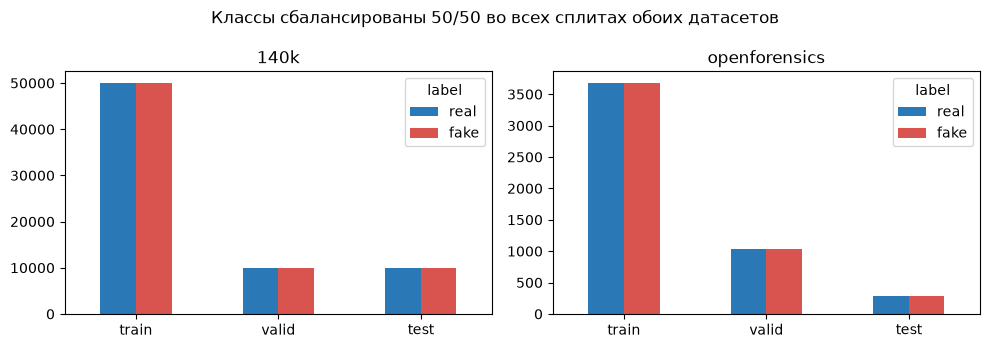

In [5]:
counts = index.groupby(["dataset", "split", "label"]).size().unstack("label").rename(columns={0: "real", 1: "fake"})
splits = ["train", "valid", "test"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ds in zip(axes, ["140k", "openforensics"]):
    counts.loc[ds].loc[splits].plot.bar(ax=ax, color=COLORS, rot=0)
    ax.set_title(ds)
    ax.set_xlabel("")
fig.suptitle("Классы сбалансированы 50/50 во всех сплитах обоих датасетов")
fig.tight_layout()
counts

**Вывод:** real и fake поровну в каждом сплите. В 140k так в исходных данных, в OpenForensics так устроена подвыборка.

| сплит | 140k real / fake | OpenForensics real / fake |
|---|---|---|
| train | 50 000 / 50 000 | 3 678 / 3 678 |
| valid | 10 000 / 10 000 | 1 036 / 1 036 |
| test | 10 000 / 10 000 | 286 / 286 |

## 3. Метаданные

Для каждого файла индекса: формат, размер, режим, качество JPEG и его таблицы квантования, субдискретизация, progressive, EXIF, ICC, полное декодирование. Кэш – `data/processed/metadata.csv`.

Различие real и fake: для числовых полей ROC-AUC по одному полю: max(AUC, 1 − AUC) и класс с бо́льшими значениями (`higher`), для категориальных – доли значений и TVD (полусумма модулей разностей долей). Порог различия: max(AUC, 1 − AUC) − 0.5 ≥ 0.05 или TVD ≥ 0.05.

In [6]:
from src.metadata import build_metadata, compare_classes

meta = build_metadata()
name = meta["path"].str.rsplit("/", n=1).str[1].str.rsplit(".", n=1).str[0]
meta["name_len"] = name.str.len()
meta["name_is_digits"] = name.str.isdigit()

numeric = ["width", "height", "file_size", "quality", "quality_error"]
categorical = ["format", "mode", "qtable_hash", "subsampling", "progressive", "has_exif", "has_icc", "opens"]
fields = {
    "140k": (numeric + ["name_len"], categorical + ["name_is_digits"]),
    "openforensics": (numeric, categorical),
}
summary = {ds: compare_classes(meta[meta["dataset"] == ds], *fields[ds]) for ds in fields}

In [7]:
summary["140k"]

,field,n_unique,real,fake,differs,auc,higher,tvd
0,width,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
1,height,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
2,file_size,19698,"median 28725.0, [13803, 51686]","median 27991.0, [15752, 53525]",False,0.544,real,NaN
3,quality,1,"median 95.0, [95, 95]","median 95.0, [95, 95]",False,NaN,NaN,NaN
4,quality_error,1,"median 0.0, [0.0, 0.0]","median 0.0, [0.0, 0.0]",False,NaN,NaN,NaN
5,name_len,2,"median 5.0, [5, 5]","median 10.0, [10, 10]",True,1.000,fake,NaN
6,format,1,JPEG: 1.0,JPEG: 1.0,False,NaN,NaN,0.0
7,mode,1,RGB: 1.0,RGB: 1.0,False,NaN,NaN,0.0
8,qtable_hash,1,c73b79bf: 1.0,c73b79bf: 1.0,False,NaN,NaN,0.0
9,subsampling,1,4:2:0: 1.0,4:2:0: 1.0,False,NaN,NaN,0.0


In [8]:
summary["openforensics"]

,field,n_unique,real,fake,differs,auc,higher,tvd
0,width,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
1,height,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
2,file_size,5962,"median 9088.0, [2117, 30790]","median 9544.5, [2285, 23788]",True,0.557,fake,NaN
3,quality,1,"median 75.0, [75, 75]","median 75.0, [75, 75]",False,NaN,NaN,NaN
4,quality_error,1,"median 0.0, [0.0, 0.0]","median 0.0, [0.0, 0.0]",False,NaN,NaN,NaN
5,format,1,JPEG: 1.0,JPEG: 1.0,False,NaN,NaN,0.0
6,mode,1,RGB: 1.0,RGB: 1.0,False,NaN,NaN,0.0
7,qtable_hash,1,0e368a84: 1.0,0e368a84: 1.0,False,NaN,NaN,0.0
8,subsampling,1,4:2:0: 1.0,4:2:0: 1.0,False,NaN,NaN,0.0
9,progressive,1,False: 1.0,False: 1.0,False,NaN,NaN,0.0


Графики – только для полей с различиями: имена файлов в 140k и размер файла в OpenForensics.

label,real,fake
name_len,,
5,70000,0
10,0,70000


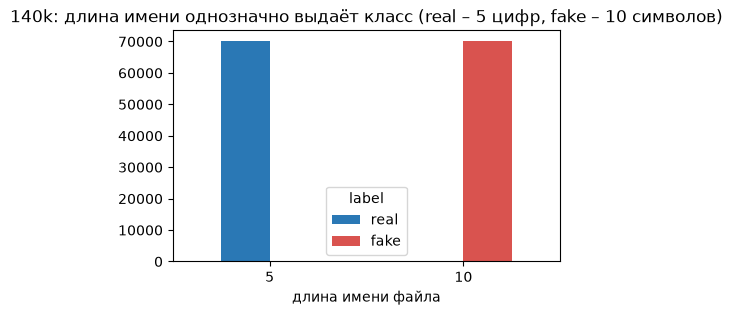

In [9]:
meta_140k = meta[meta["dataset"] == "140k"]
names = meta_140k.groupby(["name_len", "label"]).size().unstack("label", fill_value=0).rename(columns={0: "real", 1: "fake"})

ax = names.plot.bar(color=COLORS, rot=0, figsize=(5, 3))
ax.set_xlabel("длина имени файла")
ax.set_title("140k: длина имени однозначно выдаёт класс (real – 5 цифр, fake – 10 символов)")
names

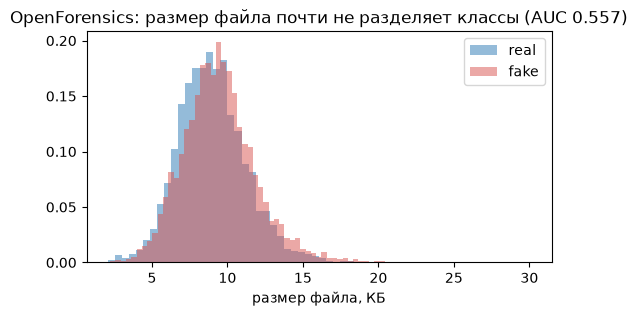

In [10]:
meta_of = meta[meta["dataset"] == "openforensics"]
auc = summary["openforensics"].set_index("field").loc["file_size", "auc"]

fig, ax = plt.subplots(figsize=(6, 3))
for label, cls in enumerate(["real", "fake"]):
    sizes = meta_of.loc[meta_of["label"] == label, "file_size"] / 1024
    ax.hist(sizes, bins=60, alpha=0.5, density=True, color=COLORS[cls], label=cls)
ax.set_xlabel("размер файла, КБ")
ax.legend()
ax.set_title(f"OpenForensics: размер файла почти не разделяет классы (AUC {auc})");

Проблемные файлы: не открываются, режим не RGB, размер отличается от самого частого в датасете.

In [11]:
common_size = meta.groupby("dataset")[["width", "height"]].agg(lambda s: s.mode()[0])
odd_size = (meta[["width", "height"]] != common_size.loc[meta["dataset"]].values).any(axis=1)
problems = meta[~meta["opens"] | (meta["mode"] != "RGB") | odd_size]

print("самый частый размер:", common_size.to_dict("index"))
print("проблемных файлов:", len(problems))
problems

самый частый размер: {'140k': {'width': 256, 'height': 256}, 'openforensics': {'width': 256, 'height': 256}}
проблемных файлов: 0


,path,dataset,split,label,format,width,height,mode,progressive,has_exif,has_icc,quality,quality_error,qtable_hash,subsampling,opens,file_size,name_len,name_is_digits


**Вывод:** технически файлы однородны. Все открываются, все JPEG RGB 256×256, без EXIF и ICC, baseline, субдискретизация 4:2:0, таблицы квантования стандартные (ошибка подгонки 0). В пределах датасета качество одинаковое у real и fake: 95 в 140k, 75 в OpenForensics. Размер файла различается слабо.

- Имена файлов выдают класс в обоих датасетах (140k: real – 5 цифр, fake – 10 символов; OpenForensics: префикс `real_*` / `fake_*`), поэтому в признаки и в детектор-читер их не включаем.
- Качество JPEG различается между датасетами (95 и 75): в кросс-датасетной проверке это нужно контролировать.

| показатель | 140k | OpenForensics |
|---|---|---|
| не открываются / не RGB / нестандартный размер | 0 / 0 / 0 | 0 / 0 / 0 |
| размер | 256×256 | 256×256 |
| качество JPEG (real = fake) | 95 | 75 |
| субдискретизация / progressive / EXIF / ICC | 4:2:0 / нет / нет / нет | 4:2:0 / нет / нет / нет |
| ROC-AUC размера файла, max(AUC, 1 − AUC) | 0.544 (real больше) | 0.557 (fake больше) |
| имя файла выдаёт класс | да (длина 5 vs 10) | да (префикс) |